# NumCompute quickstart

A tour of the toolkit from start to finish, using only Python and NumPy.

**Dataset.** We use the Titanic passenger list (`demo/data/train.csv`, from Kaggle): 891 passengers and 12 columns,
including ticket class, name, sex, age, fare, boarding port (`Embarked`) and whether they survived.
It is a good test because it is messy: 177 ages are missing, two boarding ports are blank, names contain
commas inside quotes (`"Braund, Mr. Owen Harris"`), and many passengers share the same class or fare (ties).

| Step | Module |
|---|---|
| 1. Read the CSV (missing values, quoted text, chunks) | `io` |
| 2. Impute, scale and one-hot encode | `preprocessing` |
| 3. Top-k, quickselect, binary search | `sort_search` |
| 4. Ranks with ties, percentiles | `rank` |
| 5. Statistics, histogram, quantiles, streaming stats | `stats` |
| 6. Finite-difference gradients and Jacobians | `optim` |
| 7. Pipeline, a simple model, metrics | `pipeline`, `metrics`, `utils` |
| 8. Benchmarks: Python loops vs vectorised code | `benchmarking` |

In [19]:
from pathlib import Path

import numpy as np
import svgplot  # demo/svgplot.py: small SVG charts written with NumPy only

from numcompute import io, metrics, optim, rank, sort_search, stats, utils
from numcompute import preprocessing as pp
from numcompute.pipeline import ColumnSelector, Estimator, FeatureUnion, Pipeline

np.set_printoptions(precision=3, suppress=True)
DATA = Path("data") if Path("data/train.csv").exists() else Path("demo/data")
train = DATA / "train.csv"

## 1. Reading CSV files (`io`)

`load_csv` picks columns by name. Number columns come back as floats with missing cells as NaN;
text columns are loaded with `dtype=str`, where missing cells are `""`.

In [20]:
print(io.read_header(train))

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked"]
X_num = io.load_csv(train, usecols=num_cols)
X_cat = io.load_csv(train, usecols=cat_cols, dtype=str)
names = io.load_csv(train, usecols="Name", dtype=str)[:, 0]
y = io.load_csv(train, usecols="Survived", dtype=int)[:, 0]

print("numeric", X_num.shape, "| text", X_cat.shape, "| labels", y.shape)
print("missing per numeric column:", dict(zip(num_cols, np.isnan(X_num).sum(axis=0).tolist())))
print("blank Embarked cells:", int((X_cat[:, 1] == "").sum()))
print("quoted name kept whole:", names[0])

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
numeric (891, 5) | text (891, 2) | labels (891,)
missing per numeric column: {'Pclass': 0, 'Age': 177, 'SibSp': 0, 'Parch': 0, 'Fare': 0}
blank Embarked cells: 2
quoted name kept whole: Braund, Mr. Owen Harris


In [21]:
# Three ways to handle missing cells
print(
    "skip  ->",
    io.load_csv(train, usecols=num_cols, missing="skip").shape,
    "(incomplete rows dropped)",
)
print(
    "fill  ->",
    io.load_csv(train, usecols=num_cols, fill_value=-1)[5],
    "(data row 5: missing Age -> -1)",
)
try:
    io.load_csv(train, usecols=num_cols, missing="raise")
except ValueError as err:
    print("raise ->", err)

# Streaming: read the file 250 rows at a time
print("chunk sizes:", [len(c) for c in io.iter_csv_chunks(train, chunksize=250, usecols=num_cols)])

skip  -> (714, 5) (incomplete rows dropped)
fill  -> [ 3.    -1.     0.     0.     8.458] (data row 5: missing Age -> -1)
raise -> missing value at data row 5, column 1
chunk sizes: [250, 250, 250, 141]


## 2. Preprocessing (`preprocessing`)

Every class follows the same API: `fit` learns from the data, `transform` applies it.

In [22]:
imputer = pp.SimpleImputer(strategy="median").fit(X_num)
print("medians used to fill NaN:", dict(zip(num_cols, imputer.statistics_.tolist())))
X_filled = imputer.transform(X_num)

Z = pp.StandardScaler().fit_transform(X_filled)
print("after StandardScaler  mean:", Z.mean(axis=0), " std:", Z.std(axis=0))

M = pp.MinMaxScaler(feature_range=(0, 1)).fit_transform(X_filled)
print("after MinMaxScaler    min:", M.min(axis=0), " max:", M.max(axis=0))

medians used to fill NaN: {'Pclass': 3.0, 'Age': 28.0, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 14.4542}
after StandardScaler  mean: [ 0.  0. -0. -0.  0.]  std: [1. 1. 1. 1. 1.]
after MinMaxScaler    min: [0. 0. 0. 0. 0.]  max: [1. 1. 1. 1. 1.]


In [23]:
# Text columns: fill the blank ports with the most common one, then one-hot encode
cat_imputer = pp.SimpleImputer(strategy="most_frequent", missing_values="")
X_cat_filled = cat_imputer.fit_transform(X_cat)
print("blank Embarked filled with:", cat_imputer.statistics_[1])

encoder = pp.OneHotEncoder().fit(X_cat_filled)
print("categories:", [c.tolist() for c in encoder.categories_])
print(X_cat_filled[:3].tolist())
print(encoder.transform(X_cat_filled[:3]))

blank Embarked filled with: S
categories: [['female', 'male'], ['C', 'Q', 'S']]
[['male', 'S'], ['female', 'C'], ['female', 'S']]
[[0. 1. 0. 0. 1.]
 [1. 0. 1. 0. 0.]
 [1. 0. 0. 0. 1.]]


## 3. Sorting and searching (`sort_search`)

`topk` uses `np.argpartition`, so it does not sort the whole array; among equal values the lower row wins.
`quickselect` finds the k-th smallest value in expected O(n). `binary_search` looks up many values at once.

In [24]:
fare = X_num[:, num_cols.index("Fare")]
top_fares, rows = sort_search.topk(fare, 5)
print("top-5 fares:", top_fares, "rows:", rows)
for r in rows[:3]:
    print("   ", names[r])

middle = len(fare) // 2
print(
    "quickselect median fare:",
    sort_search.quickselect(fare, middle),
    "| full sort gives:",
    sort_search.stable_sort(fare)[middle],
)

positions, found = sort_search.binary_search(np.sort(fare), [7.25, 100.0, 1000.0])
print("binary_search 7.25 / 100 / 1000 -> index", positions, "found", found)

top-5 fares: [512.329 512.329 512.329 263.    263.   ] rows: [258 679 737  27  88]
    Ward, Miss. Anna
    Cardeza, Mr. Thomas Drake Martinez
    Lesurer, Mr. Gustave J
quickselect median fare: 14.4542 | full sort gives: 14.4542
binary_search 7.25 / 100 / 1000 -> index [ 70 838 891] found [ True False False]


## 4. Ranking and percentiles (`rank`)

Ticket class has many ties, which shows the three tie methods.

In [25]:
pclass = X_num[:6, 0]
print("Pclass: ", pclass)
for method in ["average", "dense", "ordinal"]:
    print(f"{method:>8}:", rank.rank(pclass, method=method))

age = X_num[:, 1]
print("\nage ranks (NaN stays NaN):", rank.rank(age[:8]))
for method in ["linear", "lower", "higher", "midpoint"]:
    print(f"age 25/50/75th percentile ({method:>8}):", rank.percentile(age, [25, 50, 75], method))

Pclass:  [3. 1. 3. 1. 3. 3.]
 average: [4.5 1.5 4.5 1.5 4.5 4.5]
   dense: [2. 1. 2. 1. 2. 2.]
 ordinal: [3. 1. 4. 2. 5. 6.]

age ranks (NaN stays NaN): [2.  6.  3.  4.5 4.5 nan 7.  1. ]
age 25/50/75th percentile (  linear): [20.125 28.    38.   ]
age 25/50/75th percentile (   lower): [20. 28. 38.]
age 25/50/75th percentile (  higher): [20.5 28.  38. ]
age 25/50/75th percentile (midpoint): [20.25 28.   38.  ]


## 5. Statistics (`stats`)

`axis=0` gives one value per column. By default a NaN makes the result NaN; `ignore_nan=True` leaves NaN out.

In [26]:
print("mean (NaN propagates):", stats.mean(X_num, axis=0))
print("mean (ignore_nan)    :", stats.mean(X_num, axis=0, ignore_nan=True))
print("std  (ignore_nan)    :", stats.std(X_num, axis=0, ignore_nan=True))
print("var  (ddof=1)        :", stats.var(X_num, axis=0, ddof=1, ignore_nan=True))
print("median               :", stats.median(X_num, axis=0, ignore_nan=True))
print("min                  :", stats.amin(X_num, axis=0, ignore_nan=True))
print("max                  :", stats.amax(X_num, axis=0, ignore_nan=True))
print("fare quantiles 10/50/90%:", stats.quantile(fare, [0.1, 0.5, 0.9]))

mean (NaN propagates): [ 2.309    nan  0.523  0.382 32.204]
mean (ignore_nan)    : [ 2.309 29.699  0.523  0.382 32.204]
std  (ignore_nan)    : [ 0.836 14.516  1.102  0.806 49.666]
var  (ddof=1)        : [   0.699  211.019    1.216    0.65  2469.437]
median               : [ 3.    28.     0.     0.    14.454]
min                  : [1.   0.42 0.   0.   0.  ]
max                  : [  3.     80.      8.      6.    512.329]
fare quantiles 10/50/90%: [ 7.55  14.454 77.958]


age histogram counts: [ 64 115 230 155  86  42  17   5] | total: 714
streaming mean: [ 2.309 29.699  0.523  0.382 32.204]
matches one-pass mean: True | std: True


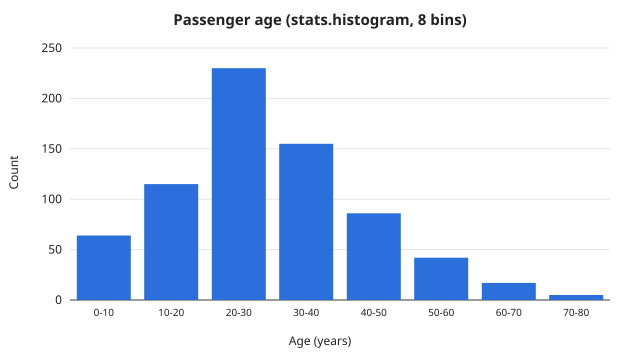

In [27]:
counts, edges = stats.histogram(age, bins=8)  # NaN ages are left out
print("age histogram counts:", counts, "| total:", counts.sum())

# Streaming (Welford): read the file 100 rows at a time and keep only running totals
running = stats.RunningStats()
for chunk in io.iter_csv_chunks(train, chunksize=100, usecols=num_cols):
    running.update(chunk)
print("streaming mean:", running.mean)
print(
    "matches one-pass mean:",
    np.allclose(running.mean, stats.mean(X_num, axis=0, ignore_nan=True)),
    "| std:",
    np.allclose(running.std(), stats.std(X_num, axis=0, ignore_nan=True)),
)

svgplot.histogram(
    counts, edges, title="Passenger age (stats.histogram, 8 bins)", xlabel="Age (years)"
)

## 6. Finite-difference gradients (`optim`)

Central differences have error O(h²), forward differences O(h). If h is too small, round-off error (about eps / h) takes over,
so the error first falls and then rises again.

In [28]:
def f(v):  # Rosenbrock function
    x, y_ = v
    return (1 - x) ** 2 + 100 * (y_ - x**2) ** 2


def f_grad(v):  # gradient worked out by hand
    x, y_ = v
    return np.array([-2 * (1 - x) - 400 * x * (y_ - x**2), 200 * (y_ - x**2)])


point = np.array([1.37, 2.11])
print("analytic:", f_grad(point))
print("central :", optim.grad(f, point))
print("forward :", optim.grad(f, point, method="forward"))

steps = 10.0 ** np.arange(-1, -13, -1.0)
err_c = [np.abs(optim.grad(f, point, h=h) - f_grad(point)).max() for h in steps]
err_f = [np.abs(optim.grad(f, point, h=h, method="forward") - f_grad(point)).max() for h in steps]
print(f"\n{'h':>8} {'central':>10} {'forward':>10}")
for h, c, fw in zip(steps, err_c, err_f):
    print(f"{h:>8.0e} {c:>10.1e} {fw:>10.1e}")

analytic: [-126.999   46.62 ]
central : [-126.999   46.62 ]
forward : [-126.992   46.621]

       h    central    forward
   1e-01    5.5e+00    7.6e+01
   1e-02    5.5e-02    7.1e+00
   1e-03    5.5e-04    7.1e-01
   1e-04    5.5e-06    7.1e-02
   1e-05    5.4e-08    7.1e-03
   1e-06    1.0e-08    7.1e-04
   1e-07    7.7e-08    7.0e-05
   1e-08    8.3e-07    7.4e-06
   1e-09    1.1e-05    9.7e-06
   1e-10    2.5e-05    7.4e-05
   1e-11    7.7e-05    4.1e-04
   1e-12    1.1e-02    1.1e-02


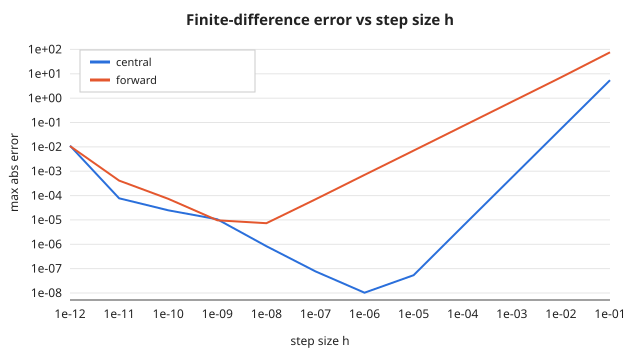

In [29]:
svgplot.line_chart(
    [("central", steps, err_c), ("forward", steps, err_f)],
    title="Finite-difference error vs step size h",
    xlabel="step size h",
    ylabel="max abs error",
    logx=True,
    logy=True,
    legend="top-left",
)

In [30]:
def F(v):  # vector function R^2 -> R^2
    return np.array([v[0] ** 2 * v[1], 5 * v[0] + np.sin(v[1])])


x1 = np.array([1.0, 2.0])
print("numerical Jacobian:\n", optim.jacobian(F, x1))
print("analytic Jacobian:\n", np.array([[2 * x1[0] * x1[1], x1[0] ** 2], [5, np.cos(x1[1])]]))

# softmax outputs always sum to 1, so each column of its Jacobian sums to 0
print(
    "softmax Jacobian column sums:",
    optim.jacobian(utils.softmax, np.array([1.0, 2.0, 3.0])).sum(axis=0),
)

numerical Jacobian:
 [[ 4.     1.   ]
 [ 5.    -0.416]]
analytic Jacobian:
 [[ 4.     1.   ]
 [ 5.    -0.416]]
softmax Jacobian column sums: [-0. -0. -0.]


## 7. Pipeline, model and metrics (`pipeline`, `metrics`)

The number columns are imputed and scaled, the text columns are imputed and one-hot encoded, and `FeatureUnion` puts the two side by side.
The model is a small nearest-centroid classifier: it stores the average passenger of each class (died / survived) and predicts the closer one,
using `utils.euclidean_distances`. We train on 80% of the passengers and evaluate on the other 20%.

In [31]:
class NearestCentroid(Estimator):
    """Predict the class whose average training row (centroid) is closest."""

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.centroids_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        return self

    def predict_proba(self, X):
        d = utils.euclidean_distances(X, self.centroids_)
        return utils.softmax(-d, axis=1)  # closer centroid -> higher probability

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


raw = np.hstack([X_num.astype(object), X_cat.astype(object)])  # 5 number + 2 text columns
numeric = Pipeline(
    [
        ("select", ColumnSelector([0, 1, 2, 3, 4], dtype=float)),
        ("impute", pp.SimpleImputer(strategy="median")),
        ("scale", pp.StandardScaler()),
    ]
)
text = Pipeline(
    [
        ("select", ColumnSelector([5, 6], dtype=str)),
        ("impute", pp.SimpleImputer(strategy="most_frequent", missing_values="")),
        ("onehot", pp.OneHotEncoder(handle_unknown="ignore")),
    ]
)
model = Pipeline(
    [("features", FeatureUnion([("num", numeric), ("text", text)])), ("clf", NearestCentroid())]
)

order = np.random.default_rng(0).permutation(len(y))
train_idx, test_idx = order[:712], order[712:]
model.fit(raw[train_idx], y[train_idx])
print(model)
print("features per passenger:", model["features"].transform(raw[:1]).shape[1])

Pipeline(features -> clf)
features per passenger: 10


In [32]:
y_test = y[test_idx]
y_pred = model.predict(raw[test_idx])
y_prob = model["clf"].predict_proba(model["features"].transform(raw[test_idx]))[:, 1]
women_rule = (X_cat[test_idx, 0] == "female").astype(int)  # simple baseline: women survive

print(f"{'':>16} {'accuracy':>9} {'precision':>10} {'recall':>7} {'F1':>6}")
for label, pred in [("nearest centroid", y_pred), ("women survive", women_rule)]:
    print(
        f"{label:>16} {metrics.accuracy(y_test, pred):>9.3f} {metrics.precision(y_test, pred):>10.3f} "
        f"{metrics.recall(y_test, pred):>7.3f} {metrics.f1(y_test, pred):>6.3f}"
    )

print(
    "\nconfusion matrix (rows = true, columns = predicted):\n",
    metrics.confusion_matrix(y_test, y_pred),
)
print("MSE of the probabilities (Brier score):", round(metrics.mse(y_test, y_prob), 4))

                  accuracy  precision  recall     F1
nearest centroid     0.793      0.750   0.696  0.722
   women survive     0.816      0.790   0.710  0.748

confusion matrix (rows = true, columns = predicted):
 [[94 16]
 [21 48]]
MSE of the probabilities (Brier score): 0.1779


The goal here is to show the pipeline and the metrics, not to build the best model. The simple rule "women survive" is a strong baseline
on this dataset and is slightly better on accuracy; the nearest-centroid model still gives useful probabilities, as the ROC curve shows.

ROC AUC: 0.85


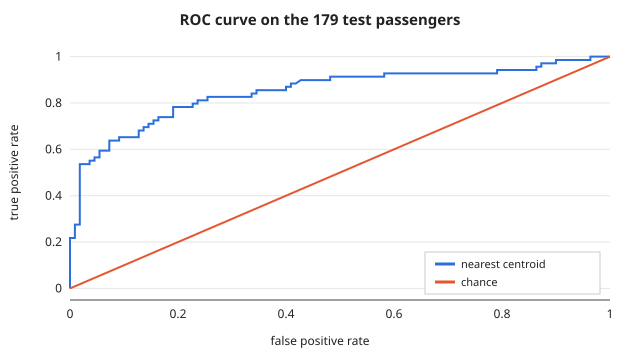

In [33]:
fpr, tpr, _ = metrics.roc_curve(y_test, y_prob)
print("ROC AUC:", round(metrics.auc(fpr, tpr), 3))
svgplot.line_chart(
    [("nearest centroid", fpr, tpr), ("chance", [0, 1], [0, 1])],
    title="ROC curve on the 179 test passengers",
    xlabel="false positive rate",
    ylabel="true positive rate",
)

## 8. Benchmarks: Python loops vs vectorised NumPy (`benchmarking`)

`compare` first checks that both versions give the same answer, then times them (after a warm-up) and reports the speed-up.
The full set is in `benchmark/run_benchmarks.py`.

In [34]:
import math

from numcompute.benchmarking import compare, environment_info, format_table

rng = np.random.default_rng(42)
x = rng.normal(size=50_000)
x_list = x.tolist()
P = rng.normal(size=(200, 8))
P_list = P.tolist()


def loop_std(values):
    m = sum(values) / len(values)
    return math.sqrt(sum((v - m) ** 2 for v in values) / len(values))


def loop_distances(points):
    return [[math.dist(a, b) for b in points] for a in points]


def loop_top10(values):
    return sorted(values, reverse=True)[:10]


rows = []
for title, funcs in [
    ("std", {"loop": lambda: loop_std(x_list), "numcompute": lambda: stats.std(x)}),
    (
        "distances",
        {
            "loop": lambda: loop_distances(P_list),
            "numcompute": lambda: utils.euclidean_distances(P),
        },
    ),
    (
        "top-10",
        {
            "loop": lambda: loop_top10(x_list),
            "numcompute": lambda: sort_search.topk(x, 10, return_indices=False),
        },
    ),
]:
    for row in compare(funcs, repeat=3):
        row["name"] = f"{title}: {row['name']}"
        rows.append(row)

print(format_table(rows))
env = environment_info()
print(f"\nPython {env['python']}, NumPy {env['numpy']}, {env['platform']}")

| Implementation | Best | Median | Speed-up |
|---|---:|---:|---:|
| std: loop | 7.79 ms | 8.57 ms | 1.0x |
| std: numcompute | 119 µs | 165 µs | 65.2x |
| distances: loop | 6.75 ms | 6.93 ms | 1.0x |
| distances: numcompute | 148 µs | 162 µs | 45.7x |
| top-10: loop | 6.16 ms | 7.61 ms | 1.0x |
| top-10: numcompute | 232 µs | 260 µs | 26.5x |

Python 3.12.13, NumPy 2.5.1, Windows-11-10.0.26300-SP0


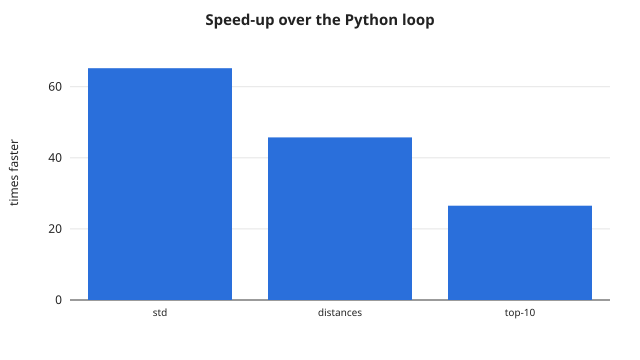

In [35]:
ours = [r for r in rows if r["name"].endswith("numcompute")]
svgplot.bar_chart(
    [r["name"].split(":")[0] for r in ours],
    [r["speedup"] for r in ours],
    title="Speed-up over the Python loop",
    ylabel="times faster",
)